# Cervical Cell Screening on the Herlev Dataset - Steps 1 to 5 (ResNet18, TensorFlow)

**One notebook, five steps, one model (ResNet18).** Run the cells from top to bottom. After every step there is a text cell that explains
*what just happened, why we did it, and how to explain it* in your own words.

| Step | Question it answers | Main output |
|---|---|---|
| **1. Load and audit** | What exactly is in the data? Is it what we think it is? | a table of all images with labels |
| **2. Clean, split, transform** | How do we prepare the data so the final score can be trusted? | train / validation / test split, 224x224 images |
| **3. The ruler and a baseline** | How do we measure "good", and what must a deep model beat? | metrics code + a simple model's score |
| **4. Train ResNet18** | Can a pretrained deep network reach 90%+ accuracy? | trained model, accuracy with confidence intervals |
| **5. Decision rule** | How do we turn a score into a safe clear / look-again / flag decision? | threshold, calibration, 3-zone triage |

**Before you run:** Runtime > Change runtime type > **T4 GPU**. Run Part 0 first. Expect roughly 15-30 minutes in total on a free GPU (a guess, not a measurement); training (Part 4) is the slow part.

**About the 90% accuracy target.** This notebook is built to give a model the best honest chance (pretrained weights, fine-tuning, flip-averaging, 3 seeds averaged),
but nobody can promise a number before seeing the data. Whatever you get, report it **with its confidence interval**, from the **test set**, used **once**.
Never raise accuracy by tuning on the test set or by making the split easier: that gives a bigger number that is not true.

# PART 0 - Setup and settings
Imports, a fixed random seed (so results repeat), the folder where results are saved (your Google Drive, so a Colab disconnect does not lose work),
and **all the settings you may want to change in one block**.

In [10]:
import os, sys, re, json, gc, time, random, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
if os.environ.get("HEADLESS") == "1":          # only used when the code is tested without a screen
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub", "h5py"], check=False)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, matthews_corrcoef, brier_score_loss,
                             roc_curve, ConfusionMatrixDisplay)

# ------------------------------------- settings -------------------------------------
SEED            = 42
IMG_SIZE        = 224            # every image is resized to 224 x 224 (the size ResNet18 was trained on)
EXPECTED_IMAGES = 917            # Herlev has 917 single-cell images
DUP_HAMMING     = 3              # two pictures whose 64-bit fingerprints differ in <= 3 bits count as near-copies
TEST_FRAC, VAL_FRAC = 0.15, 0.15 # 70 / 15 / 15 split

SEEDS           = [42, 7]  # ResNet18 is trained once per seed; the 3 results are averaged
BATCH           = 32
EPOCHS_HEAD     = 8              # phase 1: only the new classifier learns
EPOCHS_FINETUNE = 30             # phase 2: the whole network is fine-tuned (early stopping usually ends it sooner)
PATIENCE        = 6              # stop if the validation AUC has not improved for 6 epochs
LR_HEAD, LR_FINETUNE = 1e-3, 5e-5
DROPOUT         = 0.3

TARGET_SENS     = 0.95           # Step 5: "catch at least 95% of abnormal cells"
AUTO_CLEAR_MISS = 0.02           # Step 5 triage: at most 2% of abnormal cells may sit in the "auto-clear" zone
AUTO_FLAG_PPV   = 0.90           # Step 5 triage: the "auto-flag" zone should be at least 90% truly abnormal
MIN_HUMAN_SHARE = 0.10           # Step 5 triage: always send at least 10% of cells to a human (small data -> keep a margin)
N_BOOT          = 1000           # number of re-draws for confidence intervals

RUN_FINAL_TEST  = False          # keep False until EVERYTHING is final. The test set may be used only once (see the last cell).
MANUAL_PATH     = ""             # only if the Kaggle download fails: put the folder path of the unzipped dataset here
# -------------------------------------------------------------------------------------

QUICK_TEST = os.environ.get("QUICK_TEST") == "1"     # testing switch for the author of this notebook; ignore it
if QUICK_TEST:
    SEEDS = [42, 7]; EPOCHS_HEAD = EPOCHS_FINETUNE = 2; N_BOOT = 300

RUN_FINAL_TEST = RUN_FINAL_TEST or os.environ.get("RUN_FINAL_TEST") == "1"     # (second way to switch it on, used for testing)

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/sgp_cervical")
else:
    OUT = Path(os.environ.get("OUT_DIR", "./sgp_outputs"))
for sub in ["tables", "figures", "models", "preds"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok, detail=""):
    """Print PASS or WARN for one check. It never crashes, so you can read the details."""
    print(("PASS  " if ok else "WARN  ") + name + (f"   ({detail})" if detail else ""))

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NONE - training will be slow. Switch the runtime to a T4 GPU.")
print("Results are saved in:", OUT.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.21.0
GPU: NONE - training will be slow. Switch the runtime to a T4 GPU.
Results are saved in: /content/drive/MyDrive/sgp_cervical


# PART 1 - Load and audit the data
**Goal:** turn a folder of files into one clean table with one row per cell image, and prove the data is what we think it is - *before* any model sees it.

**Why this comes first.** Every number we report later is only as trustworthy as the data behind it. Wrong labels, hidden mask files or corrupt images silently ruin results.

## 1.1 Download the dataset
`kagglehub` downloads the dataset straight from Kaggle. It may ask you to log in the first time. If it fails, download and unzip the dataset yourself, put it in Google Drive,
and write its folder path in `MANUAL_PATH` (Part 0).

In [11]:
if MANUAL_PATH:
    DATA_ROOT = Path(MANUAL_PATH)
elif os.environ.get("DATA_ROOT"):
    DATA_ROOT = Path(os.environ["DATA_ROOT"])
else:
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download("ayaanelahi/herlev-cervical-cancer-dataset"))
assert DATA_ROOT.exists(), f"Folder not found: {DATA_ROOT}"
print("Dataset folder:", DATA_ROOT)

Using Colab cache for faster access to the 'herlev-cervical-cancer-dataset' dataset.
Dataset folder: /kaggle/input/herlev-cervical-cancer-dataset


## 1.2 Build the table (one row per image) and check it
For every image file we decide three things:
1. **Is it a mask?** Herlev ships a black-and-white *mask* next to every cell (names ending in `-d`). Masks are not cells. If they leak into training, every score is meaningless, so we separate them.
2. **Which of the 7 classes is it?** We read it from the folder / file name.
3. **Normal or abnormal?** Superficial, intermediate and columnar cells are **normal**; mild, moderate, severe dysplasia and carcinoma in situ are **abnormal**.

**Abnormal is our "positive" class**: it is the thing we must not miss.

Image files found    : 917
  mask files (dropped): 0
  real cell images    : 917
  could not be labelled: 0

SANITY CHECKS
PASS  cell-image count is 917   (found 917)
PASS  all 7 classes present   (found 7)
PASS  normal / abnormal counts match the Herlev paper (242 / 675)   ({'abnormal': 675, 'normal': 242})

IMAGES PER CLASS
class7
superficial            74
intermediate           70
columnar               98
mild_dysplasia        182
moderate_dysplasia    146
severe_dysplasia      197
carcinoma_in_situ     150

Share of abnormal cells: 73.6%  -> a 'dumb' model that always says 'abnormal' would already be 73.6% accurate.
This is why accuracy alone can mislead, and why Part 3 builds a better ruler.

Image sizes (pixels):
       width  height
count  917.0   917.0
mean   156.0   140.0
std     95.0    80.0
min     40.0    32.0
25%     90.0    82.0
50%    124.0   113.0
75%    191.0   169.0
max    768.0   439.0


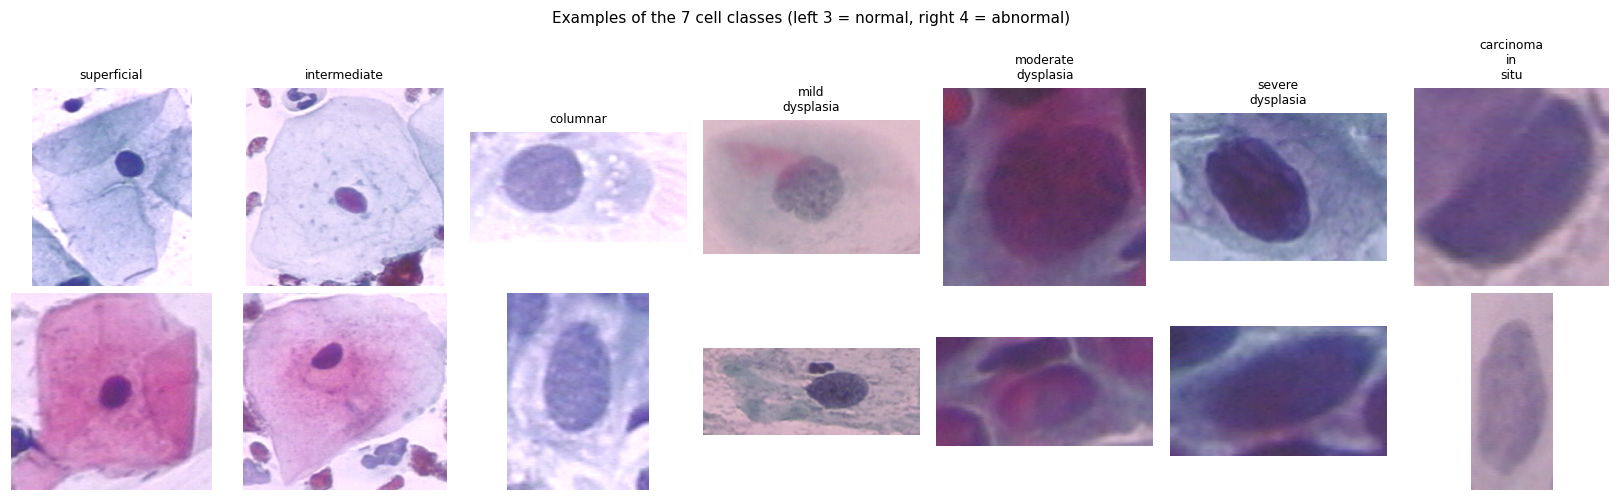

In [12]:
IMG_EXT = {".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"}
CLASS_ORDER = ["superficial", "intermediate", "columnar",
               "mild_dysplasia", "moderate_dysplasia", "severe_dysplasia", "carcinoma_in_situ"]
NORMAL_CLASSES = set(CLASS_ORDER[:3])
CLASS_REGEX = {                                   # word patterns that identify each class in a path
    "superficial": r"superficial|superficiel", "intermediate": r"intermediate", "columnar": r"columnar",
    "mild_dysplasia": r"light|mild", "moderate_dysplasia": r"moderate", "severe_dysplasia": r"severe",
    "carcinoma_in_situ": r"carcinoma|in[_\- ]?situ",
}

def is_mask(rel_path):
    """A file is a mask if its name ends in -d or _d, or 'mask'/'segment' appears in its path."""
    stem = rel_path.stem.lower()
    parts = [part.lower() for part in rel_path.parts]
    return bool(re.search(r"[-_]d$", stem)) or any(("mask" in part) or ("segment" in part) for part in parts)

def infer_class(rel_path):
    """Return the single matching class name, or None if none or several match."""
    text = "/".join(rel_path.parts[:-1] + (rel_path.stem,)).lower()
    hits = [name for name, pattern in CLASS_REGEX.items() if re.search(pattern, text)]
    return hits[0] if len(hits) == 1 else None

rows = []
for path in sorted(DATA_ROOT.rglob("*")):                       # go through every file in the dataset folder
    if path.is_file() and path.suffix.lower() in IMG_EXT:
        rel = path.relative_to(DATA_ROOT)
        rows.append({"rel_path": str(rel), "abs_path": str(path), "is_mask": is_mask(rel), "class7": infer_class(rel)})
all_images = pd.DataFrame(rows)

cells = all_images[~all_images["is_mask"]].copy()               # keep real cell images only
cells["label"] = cells["class7"].map(lambda c: None if c is None else ("normal" if c in NORMAL_CLASSES else "abnormal"))

print(f"Image files found    : {len(all_images)}")
print(f"  mask files (dropped): {int(all_images['is_mask'].sum())}")
print(f"  real cell images    : {len(cells)}")
print(f"  could not be labelled: {int(cells['class7'].isna().sum())}")
cells = cells[cells["class7"].notna()].reset_index(drop=True)

# open every image: is it readable, and how big is it?
widths, heights, readable = [], [], []
for path in cells["abs_path"]:
    try:
        with Image.open(path) as im:
            im.verify()                                          # checks the file is not corrupt
        with Image.open(path) as im:
            widths.append(im.width); heights.append(im.height); readable.append(True)
    except Exception:
        widths.append(0); heights.append(0); readable.append(False)
cells["width"], cells["height"], cells["readable"] = widths, heights, readable
cells = cells[cells["readable"]].reset_index(drop=True)

print("\nSANITY CHECKS")
check("cell-image count is 917", len(cells) == EXPECTED_IMAGES, f"found {len(cells)}")
check("all 7 classes present", cells["class7"].nunique() == 7, f"found {cells['class7'].nunique()}")
check("normal / abnormal counts match the Herlev paper (242 / 675)", cells["label"].value_counts().to_dict() == {"abnormal": 675, "normal": 242},
      str(cells["label"].value_counts().to_dict()))

print("\nIMAGES PER CLASS")
class_table = cells["class7"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)
print(class_table.to_string())
share_abnormal = (cells["label"] == "abnormal").mean()
print(f"\nShare of abnormal cells: {share_abnormal:.1%}  -> a 'dumb' model that always says 'abnormal' would already be {share_abnormal:.1%} accurate.")
print("This is why accuracy alone can mislead, and why Part 3 builds a better ruler.")
print("\nImage sizes (pixels):")
print(cells[["width", "height"]].describe().round(0).to_string())

fig, axes = plt.subplots(2, 7, figsize=(15, 4.6))
for col, cls in enumerate(CLASS_ORDER):                          # one example image per class (two rows = two different examples)
    examples = cells[cells["class7"] == cls].head(2)
    for row in range(2):
        ax = axes[row, col]; ax.axis("off")
        if row < len(examples):
            ax.imshow(Image.open(examples.iloc[row]["abs_path"]).convert("RGB"))
        if row == 0:
            ax.set_title(cls.replace("_", "\n"), fontsize=8)
plt.suptitle("Examples of the 7 cell classes (left 3 = normal, right 4 = abnormal)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p1_examples.png"); plt.show()

cells.to_csv(OUT / "tables" / "manifest.csv", index=False)

### What just happened in Part 1, and why
* **We built a table (the "manifest")** with one row per real cell image: its path, its 7-class name, its normal/abnormal label, and its size.
  Everything later reads from this table, so there is one source of truth.
* **We removed mask files.** They look like images but are not cells.
* **We checked the data against known facts** (917 images, 7 classes, 242 normal / 675 abnormal). If a check prints WARN, stop and look: something is off.
* **We found the class imbalance:** about three quarters of the cells are abnormal. A model that always answers "abnormal" scores that same share as "accuracy" without learning anything.
  So an accuracy of 90% is good, but only meaningful next to the **always-abnormal** reference of about 74%.
* **We saw the image sizes are all different.** Neural networks need one fixed size, which is why Part 2 resizes.

**How to explain it in the review:** "Before modelling we audited the data: separated masks, labelled 7 classes into normal / abnormal, verified the counts, and noticed the 74 / 26 class imbalance, which shapes how we evaluate."

# PART 2 - Clean, split and transform
**Goal:** prepare the data so that the final score can be **trusted**.

**Golden order:** clean the data, **then** split it, **then** compute anything that learns from the data. Doing it in another order leaks information from the test set into training (*data leakage*).

**Why we cannot use the raw data directly**
| Problem | What goes wrong | What we do |
|---|---|---|
| Near-copies of the same cell exist | A copy in train and a copy in test lets the model memorise instead of learn, so the score is fake | Group copies; keep each group on one side only |
| Images have different sizes | A network needs a fixed input size | Resize to 224 x 224 without stretching the cell |
| No fixed split | If each step re-splits, results cannot be compared | Decide the split once and save it |
| Reading 917 files for every epoch | Very slow | Keep all images in one array in memory |

## 2.1 Find duplicates and group them
* **Exact copies:** files with identical bytes get the same **MD5 fingerprint**. We keep one and drop the rest. If identical bytes carry *different* labels, we drop all of them (we cannot know which label is right).
* **Near-copies:** the **dHash** is a tiny 64-bit fingerprint of a picture (shrink to 9 x 8 grey, then record whether each pixel is brighter than its left neighbour). Two pictures with a fingerprint distance of 3 bits or fewer **and the same width and height** count as near-copies.
* **Groups:** if A~B and B~C, then A, B and C are one group (a "family" of the same cell). We do this with a tiny *union-find*: every image starts as its own group leader, and each near-copy pair merges two groups.
* **Safety valve:** real duplicate families are small. A group larger than 5 means the detector over-matched, so those images are treated individually.

In [13]:
df = cells.copy()
df["image_id"] = np.arange(len(df))
n_start = len(df)

def file_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = [file_md5(p) for p in df["abs_path"]]

# exact copies carrying DIFFERENT labels: remove all of them
n_labels_per_md5 = df.groupby("md5")["class7"].transform("nunique")
conflict = n_labels_per_md5 > 1
print(f"Images whose identical copy has a different label: {int(conflict.sum())} (removed)")
df = df[~conflict]
# remaining exact copies: keep the first one
is_extra_copy = df.duplicated(subset="md5", keep="first")
print(f"Extra exact copies removed: {int(is_extra_copy.sum())}")
df = df[~is_extra_copy].reset_index(drop=True)

def dhash(path):
    """64-bit visual fingerprint: is each pixel brighter than its left neighbour?"""
    with Image.open(path) as im:
        small = im.convert("L").resize((9, 8), Image.Resampling.LANCZOS)
    pixels = np.asarray(small, dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()

N = len(df)
fingerprints = np.zeros((N, 64), dtype=bool)
for i, path in enumerate(df["abs_path"]):                        # fingerprint of every image
    fingerprints[i] = dhash(path)

widths_arr, heights_arr = df["width"].to_numpy(), df["height"].to_numpy()
pairs = []                                                       # near-copy pairs (i, j)
for i in range(N - 1):                                           # compare image i with every LATER image
    distance = (fingerprints[i + 1:] != fingerprints[i]).sum(axis=1)
    same_size = (widths_arr[i + 1:] == widths_arr[i]) & (heights_arr[i + 1:] == heights_arr[i])
    for k in np.where((distance <= DUP_HAMMING) & same_size)[0]:
        pairs.append((i, i + 1 + k))
print(f"Near-copy pairs found: {len(pairs)}")

# union-find: merge the two groups of every near-copy pair
parent = list(range(N))
def find_leader(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
for i, j in pairs:
    li, lj = find_leader(i), find_leader(j)
    if li != lj:
        parent[lj] = li
df["group_id"] = [find_leader(i) for i in range(N)]

# safety valve: break up oversized groups
group_size = df.groupby("group_id")["image_id"].transform("size")
too_big = (group_size > 5).to_numpy()
check("no oversized duplicate groups", not too_big.any(), f"{int(too_big.sum())} images were in oversized groups and are now treated individually" if too_big.any() else "")
if too_big.any():
    df.loc[too_big, "group_id"] = N + np.flatnonzero(too_big)
group_size = df.groupby("group_id")["image_id"].transform("size")
print(f"Images that have at least one near-copy: {int((group_size > 1).sum())} (in {df.loc[group_size > 1, 'group_id'].nunique()} groups)")
print(f"Images kept after cleaning: {len(df)} of {n_start}")

Images whose identical copy has a different label: 0 (removed)
Extra exact copies removed: 0
Near-copy pairs found: 0
PASS  no oversized duplicate groups
Images that have at least one near-copy: 0 (in 0 groups)
Images kept after cleaning: 917 of 917


## 2.2 Split into train 70% / validation 15% / test 15%
| Split | Analogy | Used for |
|---|---|---|
| **Train** | the textbook | the model learns from it |
| **Validation** | practice exams | choose settings, stop training at the right time, choose the decision threshold |
| **Test** | the real exam | used **once**, at the very end, for the honest final number |

**Two rules:**
1. **Stratified by the 7 classes**: every split gets the same share of every class (otherwise the test set might hold almost no "superficial" cells).
2. **Group-aware**: we split *groups*, not single images, so a family of near-copies never ends up on both sides.

`random_state=SEED` makes the split identical every run. We then **check** the promises instead of trusting the code.

In [14]:
group_table = (df.groupby("group_id").agg(class7=("class7", lambda s: s.value_counts().index[0])).reset_index())
assert group_table["class7"].value_counts().min() >= 2, "A class has fewer than 2 groups - cannot split it. Check the duplicate groups."

trainval_groups, test_groups = train_test_split(group_table, test_size=TEST_FRAC, stratify=group_table["class7"], random_state=SEED)
train_groups, val_groups = train_test_split(trainval_groups, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                            stratify=trainval_groups["class7"], random_state=SEED)
split_of_group = {}
for split_name, part in [("train", train_groups), ("val", val_groups), ("test", test_groups)]:
    for gid in part["group_id"]:                                 # note which split each group belongs to
        split_of_group[gid] = split_name
df["split"] = df["group_id"].map(split_of_group)
df["is_abnormal"] = (df["label"] == "abnormal").astype(int)      # 1 = abnormal = the positive class
df["pos"] = np.arange(len(df))                                   # row number = position in the image array (next cell)

print("VERIFYING THE SPLIT")
check("every image has a split", df["split"].notna().all())
groups_in_several_splits = df.groupby("group_id")["split"].nunique()
check("no duplicate group appears in two splits (no leakage)", (groups_in_several_splits == 1).all())
shares = df["split"].value_counts(normalize=True).reindex(["train", "val", "test"])
check("split sizes are about 70 / 15 / 15", abs(shares["train"] - 0.70) < 0.05 and abs(shares["val"] - 0.15) < 0.05, str(shares.round(3).to_dict()))
check("every class is present in every split", (pd.crosstab(df["class7"], df["split"]) > 0).all().all())

print("\nIMAGES PER CLASS IN EACH SPLIT")
print(pd.crosstab(df["class7"], df["split"])[["train", "val", "test"]].reindex(CLASS_ORDER).to_string())
print("\nSHARE OF ABNORMAL IN EACH SPLIT (should be similar):")
print(df.groupby("split")["is_abnormal"].mean().reindex(["train", "val", "test"]).round(3).to_string())

VERIFYING THE SPLIT
PASS  every image has a split
PASS  no duplicate group appears in two splits (no leakage)
PASS  split sizes are about 70 / 15 / 15   ({'train': 0.699, 'val': 0.15, 'test': 0.15})
PASS  every class is present in every split

IMAGES PER CLASS IN EACH SPLIT
split               train  val  test
class7                              
superficial            52   11    11
intermediate           49   11    10
columnar               68   15    15
mild_dysplasia        128   27    27
moderate_dysplasia    102   22    22
severe_dysplasia      137   30    30
carcinoma_in_situ     105   22    23

SHARE OF ABNORMAL IN EACH SPLIT (should be similar):
split
train    0.736
val      0.732
test     0.739


## 2.3 Resize every image to 224 x 224
* A network needs a fixed input size. **Stretching** a long thin cell into a square would distort its shape - and shape is exactly what separates normal from abnormal.
* So we **scale the image to fit** inside 224 x 224 and fill the leftover border with the image's own border colour (`ImageOps.pad`).
* The result is stored as `uint8` numbers 0..255 in one array `X` of shape (917, 224, 224, 3). It is small (about 140 MB), so we keep it in memory: training becomes much faster than reading files each epoch.

**Note:** we do *not* compute a mean / std here. The ResNet18 we use contains its own input-normalising layer trained on ImageNet (Part 4), so raw 0..255 pixels are exactly what it expects.

  resized 250/917
  resized 500/917
  resized 750/917
X shape: (917, 224, 224, 3) | dtype: uint8 | pixel range: 0 to 255


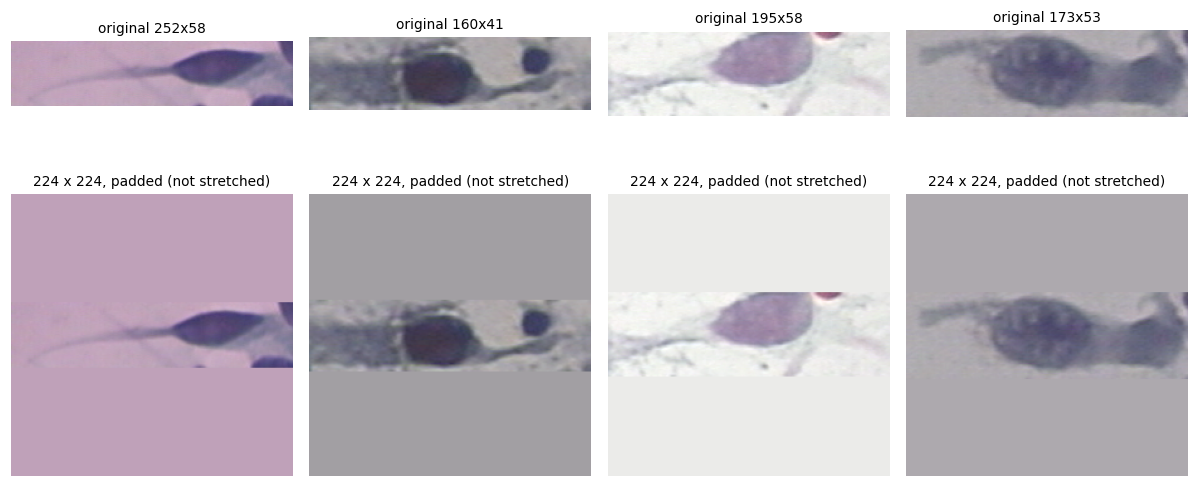


train 641 images (472 abnormal / 169 normal) | validation 138 | test 138 -> LOCKED
class weights computed from TRAIN only {0: normal, 1: abnormal}: {0: 1.896, 1: 0.679}


In [15]:
def load_and_pad(path, size):
    """Read one image and return a (size, size, 3) uint8 array, keeping the cell's proportions."""
    with Image.open(path) as raw:
        rgb = raw.convert("RGB")
    arr = np.asarray(rgb)
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]], axis=0)        # all edge pixels
    fill = tuple(int(v) for v in np.median(border, axis=0))                          # their median colour
    return np.asarray(ImageOps.pad(rgb, (size, size), method=Image.Resampling.BICUBIC, color=fill))

X = np.zeros((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
for i, path in enumerate(df["abs_path"]):                        # resize every image into slot i of X
    X[i] = load_and_pad(path, IMG_SIZE)
    if (i + 1) % 250 == 0:
        print(f"  resized {i + 1}/{len(df)}")
print("X shape:", X.shape, "| dtype:", X.dtype, "| pixel range:", int(X.min()), "to", int(X.max()))

fig, axes = plt.subplots(2, 4, figsize=(11, 5.4))
elongated = (df["width"] / df["height"]).sub(1).abs().sort_values(ascending=False).index[:4]     # the most non-square images
for col, idx in enumerate(elongated):
    axes[0, col].imshow(Image.open(df.loc[idx, "abs_path"]).convert("RGB")); axes[0, col].set_title(f"original {df.loc[idx, 'width']}x{df.loc[idx, 'height']}", fontsize=9)
    axes[1, col].imshow(X[idx]); axes[1, col].set_title("224 x 224, padded (not stretched)", fontsize=9)
    axes[0, col].axis("off"); axes[1, col].axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures" / "p2_resize.png"); plt.show()

# save the split table and the images, so a restarted session can reload them
df.drop(columns=["abs_path"]).to_csv(OUT / "tables" / "splits.csv", index=False)
np.save(OUT / "tables" / "images_224.npy", X)

train_idx = df.index[df["split"] == "train"].to_numpy()
val_idx   = df.index[df["split"] == "val"].to_numpy()
test_idx  = df.index[df["split"] == "test"].to_numpy()          # only the POSITIONS are kept; test images are not touched until the very end

Xtr, ytr = X[train_idx], df.loc[train_idx, "is_abnormal"].to_numpy().astype("float32")
Xva, yva = X[val_idx],   df.loc[val_idx,   "is_abnormal"].to_numpy().astype("float32")
class7_val = df.loc[val_idx, "class7"].to_numpy()

n_abn, n_nor = int(ytr.sum()), int(len(ytr) - ytr.sum())
class_weight = {0: len(ytr) / (2 * n_nor), 1: len(ytr) / (2 * n_abn)}     # rarer class (normal) gets the larger weight
print(f"\ntrain {len(ytr)} images ({n_abn} abnormal / {n_nor} normal) | validation {len(yva)} | test {len(test_idx)} -> LOCKED")
print("class weights computed from TRAIN only {0: normal, 1: abnormal}:", {k: round(v, 3) for k, v in class_weight.items()})

### What just happened in Part 2, and why
* **Cleaning:** we removed exact copies and conflicting copies, then found *near*-copies with a visual fingerprint and put each family of the same cell into one **group**.
* **Splitting:** we cut the data into train (70%), validation (15%) and test (15%) **by group** and **stratified by class**. Then we *verified* the promises: no group in two splits, similar class mix everywhere.
  The checks print PASS / WARN so a mistake cannot hide.
* **Transforming:** every image became a 224 x 224 array without distortion; class weights came from the **train** split only.
* **Why this matters for the score:** without grouping, a near-copy of a training cell could sit in the test set, the model would recognise it, and the accuracy would look great but mean nothing.
  Many published numbers on small datasets suffer from exactly this. Our split is the reason you can defend the final number.
* **What we saved:** `splits.csv` (one row per image with its group and split), `images_224.npy`, `manifest.csv`.

**How to explain it in the review:** "We cleaned duplicates, grouped near-identical cells so no cell family is in two splits, split 70/15/15 stratified by class, and resized without distortion. The test set stays locked until the end."

# PART 3 - The ruler (how we measure) and a baseline to beat
**Goal:** (a) build one function that scores *any* model the same way, (b) get the score of a few "no-brainer" models, so we know what a deep model must beat.

## The four counts everything is built from
Abnormal is the positive class.
| Count | Meaning |
|---|---|
| **TP** | abnormal, and we said abnormal (a correct catch) |
| **FN** | abnormal, but we said normal (**a missed abnormal cell - the dangerous mistake**) |
| **FP** | normal, but we said abnormal (a false alarm) |
| **TN** | normal, and we said normal (a correct clear) |

| Metric | Plain meaning |
|---|---|
| **Accuracy** | share of all cells answered correctly (the number your faculty asked about) |
| **Sensitivity** (recall) | of the truly abnormal cells, how many did we catch? `TP / (TP + FN)` |
| **Specificity** | of the truly normal cells, how many did we clear? `TN / (TN + FP)` |
| **Precision** | when we say abnormal, how often are we right? |
| **F1** | one number balancing precision and sensitivity |
| **Balanced accuracy** | the average of sensitivity and specificity (fair under imbalance) |
| **MCC** | correlation between prediction and truth, -1 to +1; 0 = no better than guessing |
| **ROC-AUC** | chance that a random abnormal cell gets a higher score than a random normal one (0.5 = guessing, 1 = perfect) |
| **Brier score** | how good the probabilities are (lower is better) |

A **confidence interval (CI)** says how shaky a number is. We get it by the **bootstrap**: re-draw the images with replacement many times, re-measure, and take the middle 95% of the results.

In [16]:
def safe_div(a, b):
    return a / b if b else 0.0

def evaluate(y_true, p_abnormal, threshold=0.5):
    """THE RULER. y_true: 1 = abnormal, 0 = normal. p_abnormal: model's probability of 'abnormal'."""
    y_true = np.asarray(y_true).astype(int); p_abnormal = np.asarray(p_abnormal, dtype=float)
    pred = (p_abnormal >= threshold).astype(int)                 # call it abnormal if the score reaches the threshold
    tp = int(((pred == 1) & (y_true == 1)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    sens, spec = safe_div(tp, tp + fn), safe_div(tn, tn + fp)
    prec = safe_div(tp, tp + fp)
    f1 = safe_div(2 * prec * sens, prec + sens)
    try:
        auc = roc_auc_score(y_true, p_abnormal)
    except ValueError:                                           # happens if only one class is present
        auc = np.nan
    return {"tp": tp, "fn": fn, "fp": fp, "tn": tn, "accuracy": (tp + tn) / len(y_true), "sensitivity": sens,
            "specificity": spec, "precision": prec, "f1": f1, "balanced_acc": (sens + spec) / 2,
            "mcc": matthews_corrcoef(y_true, pred), "roc_auc": auc, "brier": brier_score_loss(y_true, p_abnormal)}

def bootstrap_ci(y_true, p_abnormal, metric, threshold=0.5, n_boot=None, seed=SEED):
    """95% interval of one metric: re-draw the data with replacement, re-measure, take the middle 95%."""
    n_boot = n_boot or N_BOOT
    y_true, p_abnormal = np.asarray(y_true), np.asarray(p_abnormal)
    rng = np.random.default_rng(seed); n = len(y_true); values = []
    for _ in range(n_boot):
        pick = rng.integers(0, n, size=n)                        # draw n images with replacement
        if y_true[pick].sum() in (0, n):                         # skip draws with only one class
            continue
        values.append(evaluate(y_true[pick], p_abnormal[pick], threshold)[metric])
    return tuple(np.percentile(values, [2.5, 97.5]))

# test the ruler on an example we can check by hand
demo = evaluate([1, 1, 1, 1, 0, 0, 0, 0, 0, 0], [0.9, 0.8, 0.7, 0.2, 0.1, 0.3, 0.6, 0.4, 0.2, 0.05])
check("ruler: accuracy 0.8, sensitivity 0.75, specificity 0.833 on a hand-made example",
      abs(demo["accuracy"] - 0.8) < 1e-9 and abs(demo["sensitivity"] - 0.75) < 1e-9 and abs(demo["specificity"] - 5 / 6) < 1e-9)

PASS  ruler: accuracy 0.8, sensitivity 0.75, specificity 0.833 on a hand-made example


## 3.1 "No-brainer" models and a simple classical baseline
1. **Always say abnormal** and **flip a coin**: they show why accuracy alone is not enough.
2. **A simple classical model (Random Forest)** on a few hand-made numbers per image: average colour, brightness, how much of the cell is dark (the nucleus), and how sharp its edges are.
   It does not learn from pixels; a human decided what to measure. If a deep network cannot clearly beat this, its extra complexity is not justified.

**Features are computed on the middle part of each image** (the centre 60%), so the grey padding from Part 2 cannot act as a shortcut.
**Dark fraction** = share of pixels clearly darker than the image's typical brightness (a cheap stand-in for nucleus size).

In [17]:
def handcrafted_features(img):
    """12 simple numbers describing one 224x224 RGB image (uint8)."""
    m = int(IMG_SIZE * 0.2)
    crop = img[m:-m, m:-m].astype("float32")                     # centre 60%
    gray = crop.mean(axis=2)
    gy, gx = np.gradient(gray)
    edge = np.sqrt(gx ** 2 + gy ** 2)                            # how sharply brightness changes
    dark = (gray < (np.median(gray) - 25)).mean()                # share of clearly dark pixels
    return np.array([*crop.mean(axis=(0, 1)), *crop.std(axis=(0, 1)),      # colour mean (3) and spread (3)
                     gray.mean(), gray.std(), np.percentile(gray, 10), dark, edge.mean()])   # brightness, darkest 10%, dark share, edge strength

feat_names = ["R_mean", "G_mean", "B_mean", "R_std", "G_std", "B_std", "bright_mean", "bright_std", "bright_p10", "dark_fraction", "edge_mean"]
F = np.array([handcrafted_features(img) for img in X])           # one row of numbers per image
Ftr, Fva = F[train_idx], F[val_idx]
check("feature table has no missing or infinite values", bool(np.isfinite(F).all()), f"{F.shape[0]} images x {F.shape[1]} features")

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(Ftr, ytr)                                                  # learn from TRAIN only
p_rf = rf.predict_proba(Fva)[:, 1]                                # probability of abnormal for the validation images

baselines = {
    "always say 'abnormal'": np.ones(len(yva)),
    "flip a coin": np.random.default_rng(SEED).random(len(yva)),
    "Random Forest on 11 hand-made features": p_rf,
}
rows = []
for name, p in baselines.items():
    r = evaluate(yva, p)
    rows.append({"model": name, "accuracy": r["accuracy"], "sensitivity": r["sensitivity"], "specificity": r["specificity"],
                 "balanced_acc": r["balanced_acc"], "roc_auc": r["roc_auc"], "mcc": r["mcc"]})
baseline_table = pd.DataFrame(rows).round(3)
print("BASELINES ON THE VALIDATION SET")
print(baseline_table.to_string(index=False))

rf_acc_ci = bootstrap_ci(yva, p_rf, "accuracy"); rf_auc_ci = bootstrap_ci(yva, p_rf, "roc_auc")
print(f"\nRandom Forest accuracy 95% CI: {rf_acc_ci[0]:.3f} to {rf_acc_ci[1]:.3f}     AUC 95% CI: {rf_auc_ci[0]:.3f} to {rf_auc_ci[1]:.3f}")
importance = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).round(3)
print("\nWhich hand-made numbers did the forest use most?"); print(importance.head(5).to_string())
bar = {"model": "Random Forest", "val_accuracy": float(baseline_table.iloc[2]["accuracy"]), "val_auc": float(baseline_table.iloc[2]["roc_auc"]),
       "val_auc_ci": [float(rf_auc_ci[0]), float(rf_auc_ci[1])]}
(OUT / "tables" / "baseline_bar.json").write_text(json.dumps(bar, indent=2))

PASS  feature table has no missing or infinite values   (917 images x 11 features)
BASELINES ON THE VALIDATION SET
                                 model  accuracy  sensitivity  specificity  balanced_acc  roc_auc   mcc
                 always say 'abnormal'     0.732        1.000        0.000         0.500    0.500 0.000
                           flip a coin     0.507        0.485        0.568         0.526    0.531 0.047
Random Forest on 11 hand-made features     0.877        0.980        0.595         0.787    0.909 0.672

Random Forest accuracy 95% CI: 0.819 to 0.935     AUC 95% CI: 0.839 to 0.969

Which hand-made numbers did the forest use most?
edge_mean        0.157
dark_fraction    0.145
bright_p10       0.112
B_mean           0.099
G_std            0.087


145

### What just happened in Part 3, and why
* **We wrote the ruler once** (`evaluate`) and will use it for every model. That is what makes comparisons fair.
* **The dumb models taught us a lesson:** "always abnormal" gets high accuracy but zero specificity - it never clears a normal cell. Accuracy alone would call it good. That is why we always report sensitivity, specificity, MCC and AUC next to accuracy.
* **The Random Forest is our bar.** It is a respectable classical model using 11 numbers a human could explain. A deep network has to beat it by more than the noise (look at the confidence interval) to justify its cost.
* **The CI is the honest part:** with a few hundred validation images, accuracy can easily wobble by several points. We say "0.93, 95% CI 0.88 to 0.97", never just "93%".
* **Feature importance** tells us what the forest looked at (for example, how much of the cell is dark). It is a first, human-readable hint at what separates normal from abnormal cells.

**How to explain it in the review:** "We built a metrics function with confidence intervals, showed that accuracy alone is misleading under class imbalance, and set a classical Random Forest as the bar the deep model must beat."

# PART 4 - Train ResNet18 (transfer learning)
**Goal:** train one deep network and measure whether it reaches **90%+ accuracy** (with sensitivity, specificity and AUC next to it).

## What is ResNet18?
A **residual network** is a deep stack of convolution layers with **skip connections**: each block adds its input back to its output (`out = block(x) + x`).
The shortcut lets signals and learning flow through many layers without fading, so deep networks train well. **18** = the number of weighted layers. It has about 11 million weights.

```
image -> first conv + pooling -> 4 stages of 2 residual blocks (64, 128, 256, 512 filters) -> average pooling -> 1 output: P(abnormal)
one residual block:  x -> BatchNorm -> ReLU -> Conv -> BatchNorm -> ReLU -> Conv -> ( + x ) -> out
```
* **Convolution:** small 3x3 "stencils" slide over the picture; each detects a pattern (an edge, a dark blob, a texture). Early layers find edges; deeper layers find shapes such as an irregular nucleus.
* **BatchNorm:** keeps the numbers inside the network well-behaved. **ReLU:** turns negatives into zero (lets the network learn curved rules). **Dropout:** randomly silences 30% of units during training so the network cannot lean on any single one.

## What is transfer learning, and why do we use it?
We have only about 640 training images. Learning to see from zero with so little data overfits. A network **pretrained on ImageNet** (1.2 million everyday photos) already knows edges, textures and shapes.
We reuse that and teach it our cells. Keras has no ResNet18, so we build it ourselves and load the published ImageNet weights into it, layer by layer. If the download fails, the code **stops with an error** instead of silently training from random weights.

## How we train (two phases)
1. **Phase 1 - head only.** The pretrained part is frozen; only the new final layer learns (learning rate 1e-3). A random new layer would otherwise send large wrong signals back into the pretrained layers.
2. **Phase 2 - fine-tune.** We unfreeze the convolution layers and train everything with a **tiny learning rate** (5e-5), so knowledge is *adjusted*, not erased. BatchNorm stays frozen (with small batches it becomes noisy).
* **Learning rate** = the size of each weight-update step. Too big: it overshoots. Too small: it crawls.
* **Early stopping** watches the validation AUC; after 6 epochs without improvement it stops and restores the best epoch (prevents overfitting).
* **Class weights** make mistakes on the rarer normal class count more.
* **Augmentation** (flips, rotations, small zoom, brightness / contrast changes) shows the network slightly changed copies of each training cell. A cell has no "right way up", so the label stays true. **Train images only.**
* **3 seeds:** one run on small data can be lucky or unlucky; we train 3 times with different randomness and average.
* **Flip-averaging (test-time augmentation):** at prediction time the model sees 4 views of each cell (as is, flipped left-right, flipped up-down, both) and we average the 4 probabilities. Free extra evidence.

## 4.1 Data pipeline and augmentation

PASS  batch shape is (batch, 224, 224, 3)   ((32, 224, 224, 3))
PASS  pixel values stay in 0..255


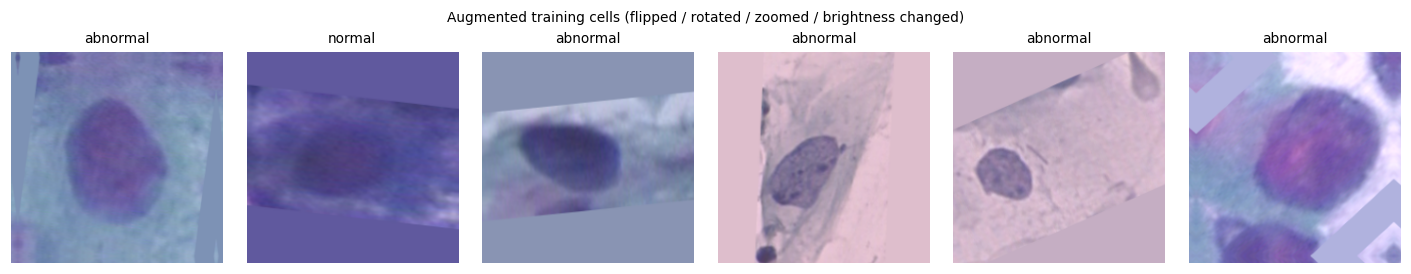

In [18]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(factor=0.5, fill_mode="reflect"),
    layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode="reflect"),
    layers.RandomBrightness(factor=0.1, value_range=(0, 255)),
    layers.RandomContrast(factor=0.1),
], name="augment")

def make_dataset(X_part, y_part, training, seed=SEED):
    """Arrays -> batches. Shuffling and augmentation only for training."""
    ds = tf.data.Dataset.from_tensor_slices((X_part, y_part))
    if training:
        ds = ds.shuffle(buffer_size=len(X_part), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

val_ds = make_dataset(Xva, yva, training=False)                  # validation: never shuffled, never augmented

xb, yb = next(iter(make_dataset(Xtr, ytr, training=True)))
check("batch shape is (batch, 224, 224, 3)", tuple(xb.shape[1:]) == (IMG_SIZE, IMG_SIZE, 3), str(tuple(xb.shape)))
check("pixel values stay in 0..255", float(tf.reduce_min(xb)) >= -1e-3 and float(tf.reduce_max(xb)) <= 255.001)
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
for k in range(6):
    axes[k].imshow(xb[k].numpy().clip(0, 255).astype("uint8")); axes[k].axis("off")
    axes[k].set_title("abnormal" if yb[k].numpy() == 1 else "normal", fontsize=9)
plt.suptitle("Augmented training cells (flipped / rotated / zoomed / brightness changed)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p4_augmented.png"); plt.show()

## 4.2 Build ResNet18 and load the ImageNet weights
The code below spells out the architecture layer by layer (so you can see the skip connections), then copies the published ImageNet arrays into the layers with the same names.
Afterwards it **proves** all 40 weighted layers were filled and that the input normaliser looks like ImageNet's (pixel means about 124 / 117 / 104). These weights expect raw 0..255 RGB pixels - exactly what we have.

In [19]:
WEIGHTS_URL = "https://github.com/qubvel/classification_models/releases/download/0.0.1/resnet18_imagenet_1000_no_top.h5"

def bn_layer(name, scale=True):
    return layers.BatchNormalization(axis=3, momentum=0.99, epsilon=2e-5, scale=scale, name=name)

def residual_block(x, filters, stride, first_in_stage, name):
    """BatchNorm-ReLU-Conv-BatchNorm-ReLU-Conv, plus the skip connection (the input added back)."""
    out = bn_layer(f"{name}_bn1")(x)
    out = layers.ReLU(name=f"{name}_relu1")(out)
    skip = layers.Conv2D(filters, 1, strides=stride, use_bias=False, name=f"{name}_sc")(out) if first_in_stage else x
    out = layers.ZeroPadding2D(1)(out)
    out = layers.Conv2D(filters, 3, strides=stride, padding="valid", use_bias=False, name=f"{name}_conv1")(out)
    out = bn_layer(f"{name}_bn2")(out)
    out = layers.ReLU(name=f"{name}_relu2")(out)
    out = layers.ZeroPadding2D(1)(out)
    out = layers.Conv2D(filters, 3, padding="valid", use_bias=False, name=f"{name}_conv2")(out)
    return layers.Add()([out, skip])

def build_backbone():
    """ResNet18 without its original classifier, with ImageNet weights loaded."""
    import h5py
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = bn_layer("bn_data", scale=False)(inputs)                 # does the ImageNet normalisation itself
    x = layers.ZeroPadding2D(3)(x)
    x = layers.Conv2D(64, 7, strides=2, padding="valid", use_bias=False, name="conv0")(x)
    x = bn_layer("bn0")(x)
    x = layers.ReLU(name="relu0")(x)
    x = layers.ZeroPadding2D(1)(x)
    x = layers.MaxPooling2D(3, strides=2, padding="valid", name="pooling0")(x)
    for stage, filters in enumerate([64, 128, 256, 512]):        # 4 stages
        for unit in range(2):                                    # 2 residual blocks per stage
            stride = 2 if (unit == 0 and stage > 0) else 1       # stages 2-4 start by halving the image size
            x = residual_block(x, filters, stride, first_in_stage=(unit == 0), name=f"stage{stage + 1}_unit{unit + 1}")
    x = bn_layer("bn1")(x)
    x = layers.ReLU(name="relu1")(x)
    backbone = keras.Model(inputs, x, name="resnet18_backbone")

    try:
        weights_file = keras.utils.get_file("resnet18_imagenet_1000_no_top.h5", WEIGHTS_URL)
    except Exception as e:
        raise RuntimeError(f"Could not download the pretrained ResNet18 weights ({e}). Check the internet connection and run again. "
                           "(Training from random weights would silently cancel transfer learning, so we stop instead.)") from e
    loaded = 0
    with h5py.File(weights_file, "r") as f:
        names_in_file = [n.decode() if isinstance(n, bytes) else n for n in f.attrs["layer_names"]]
        for layer in backbone.layers:                            # copy the arrays of every layer that has a twin in the file
            if layer.name in names_in_file:
                group = f[layer.name]
                weight_names = [w.decode() if isinstance(w, bytes) else w for w in group.attrs["weight_names"]]
                if weight_names:
                    layer.set_weights([np.array(group[w]) for w in weight_names])
                    loaded += 1
    n_weighted = sum(1 for layer in backbone.layers if layer.weights)
    check("every weighted layer received its pretrained weights", loaded == n_weighted, f"{loaded} of {n_weighted} layers")
    if loaded != n_weighted:
        raise RuntimeError("Pretrained weights did not fit the model; do not continue.")
    return backbone

def build_model():
    """Pretrained backbone + new head. Returns (model, backbone)."""
    backbone = build_backbone()
    backbone.trainable = False                                   # phase 1: backbone frozen
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = backbone(inputs, training=False)                         # training=False keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)                       # each of 512 feature maps -> one number
    x = layers.Dropout(DROPOUT)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)           # one number between 0 and 1 = P(abnormal)
    return keras.Model(inputs, outputs, name="resnet18"), backbone

def unfreeze_conv_layers(backbone):
    """Phase 2: every layer of the backbone becomes trainable, except BatchNorm layers."""
    backbone.trainable = True
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def compile_model(model, learning_rate):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="acc"), keras.metrics.AUC(name="auc")])

model_try, backbone_try = build_model()
print(f"ResNet18: {model_try.count_params():,} parameters")
bn_mean = backbone_try.get_layer("bn_data").get_weights()[1]
check("input normaliser looks like ImageNet pixel means (about 124, 117, 104)", bool((np.abs(bn_mean - [123.7, 116.3, 103.5]) < 15).all()), str(np.round(bn_mean, 1)))
keras.backend.clear_session(); del model_try, backbone_try

44920640/44920640 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
PASS  every weighted layer received its pretrained weights   (40 of 40 layers)
ResNet18: 11,187,402 parameters
PASS  input normaliser looks like ImageNet pixel means (about 124, 117, 104)   ([123.3 115.5 102.1])


## 4.3 Train (one run per seed)
**What you will see in the log:** one line per epoch with `acc`, `auc` and `loss` on training data and `val_acc`, `val_auc`, `val_loss` on validation data.
* `val_auc` and `val_acc` should climb and then flatten. Training accuracy far above validation accuracy = **overfitting** (early stopping will cut it).
* At the start of phase 2 a small dip and then a rise is normal; a crash in `val_auc` means the fine-tuning learning rate is too high.
* **A finished seed is saved at once.** If Colab disconnects, run the cells again: finished seeds are skipped.
* **Rough time:** a few minutes per seed on a free T4 GPU (an estimate, not a measurement).

In [20]:
def predict_scores(model, images, flip_average=True):
    """P(abnormal) per image. With flip_average: mean over 4 views (as is, left-right, up-down, both)."""
    arr = np.asarray(images, dtype="float32")
    views = [arr, arr[:, :, ::-1], arr[:, ::-1], arr[:, ::-1, ::-1]] if flip_average else [arr]
    scores = [model.predict(np.ascontiguousarray(v), batch_size=BATCH, verbose=0).ravel().astype(float) for v in views]
    return np.mean(scores, axis=0)

def train_one_seed(seed):
    keras.utils.set_random_seed(seed)
    model, backbone = build_model()
    train_ds = make_dataset(Xtr, ytr, training=True, seed=seed)
    stopper = lambda: keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE, restore_best_weights=True, verbose=0)

    compile_model(model, LR_HEAD)                                # phase 1: only the new head learns
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, class_weight=class_weight, callbacks=[stopper()], verbose=2)
    unfreeze_conv_layers(backbone)                               # phase 2: fine-tune the backbone ...
    compile_model(model, LR_FINETUNE)                            # ... and RE-COMPILE (required after changing what is trainable)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE, class_weight=class_weight, callbacks=[stopper()], verbose=2)

    history = {}
    for h in (h1, h2):                                           # join both phases into one list of numbers per metric
        for key, values in h.history.items():
            history.setdefault(key, []).extend([float(v) for v in values])
    model.save(OUT / "models" / f"resnet18_seed{seed}.keras")
    np.save(OUT / "preds" / f"resnet18_seed{seed}_val.npy", predict_scores(model, Xva))
    (OUT / "preds" / f"resnet18_seed{seed}_history.json").write_text(json.dumps({"history": history, "phase_boundary": len(h1.history["loss"])}))
    keras.backend.clear_session(); gc.collect()

for seed in SEEDS:
    done = (OUT / "preds" / f"resnet18_seed{seed}_history.json").exists() and (OUT / "models" / f"resnet18_seed{seed}.keras").exists()
    if done:
        print(f"[skip] seed {seed}: already finished")
        continue
    print(f"\n===== training ResNet18, seed {seed} =====")
    t0 = time.time()
    train_one_seed(seed)
    p = np.load(OUT / "preds" / f"resnet18_seed{seed}_val.npy"); r = evaluate(yva, p)
    print(f"--> seed {seed} done in {time.time() - t0:.0f}s | validation ACCURACY {r['accuracy']:.3f} | AUC {r['roc_auc']:.3f} | "
          f"sensitivity {r['sensitivity']:.3f} | specificity {r['specificity']:.3f}")

[skip] seed 42: already finished
[skip] seed 7: already finished


## 4.4 Results: accuracy, and everything next to it
* One row per seed, then the **seed-ensemble** (average of the 3 seeds' probabilities; each seed already averages 4 flips).
* **Accuracy at threshold 0.5**: "call it abnormal if P(abnormal) >= 0.5".
* **95% confidence intervals** for accuracy, sensitivity, specificity and AUC.
* Comparison with the **always-abnormal accuracy** and with the **Random Forest bar** from Part 3.
* Learning curves, ROC curve, confusion matrix and the **errors per original cell class** (which kinds of abnormal cells are missed).

EVERY SEED (validation set, threshold 0.5)
 seed  accuracy  sensitivity  specificity  roc_auc   mcc  missed  false_alarms
   42     0.913        0.931        0.865    0.980 0.783       7             5
    7     0.913        0.891        0.973    0.984 0.808      11             1

mean accuracy over seeds 0.913 +/- 0.000   (a small spread = a stable result)

SEED-ENSEMBLE (2 seeds, flip-averaged), threshold 0.5
  accuracy 0.928 | sensitivity 0.921 | specificity 0.946 | AUC 0.981 | MCC 0.829
  missed abnormal cells: 8 | false alarms: 2

95% CONFIDENCE INTERVALS
  accuracy     0.928   (95% CI 0.884 to 0.971)
  sensitivity  0.921   (95% CI 0.869 to 0.970)
  specificity  0.946   (95% CI 0.862 to 1.000)
  roc_auc      0.981   (95% CI 0.959 to 0.997)

CONTEXT:  always-abnormal accuracy 0.732 | Random Forest bar: accuracy 0.877, AUC 0.909 (CI 0.839-0.969) | ResNet18 ensemble: accuracy 0.928, AUC 0.981
VERDICT on AUC: clearly better than the Random Forest
TARGET: accuracy >= 90% on validation -

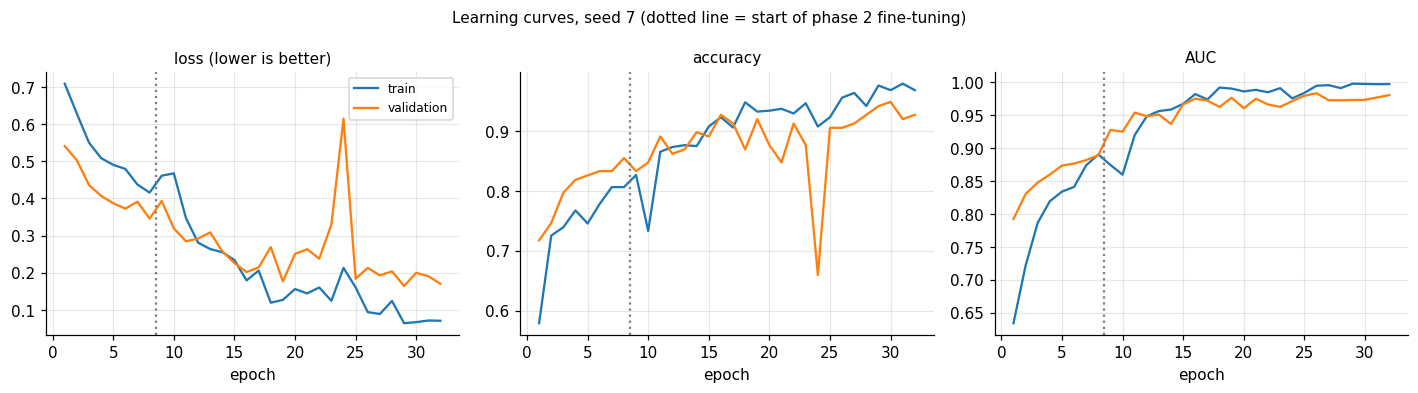

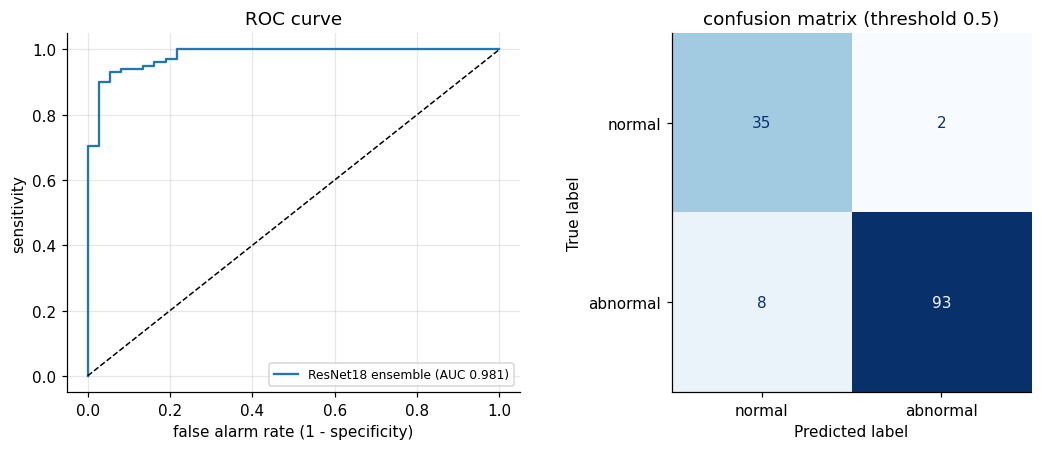


ERRORS PER CELL CLASS (validation, threshold 0.5) - with ~10-30 cells per class treat these as hints, not conclusions
        cell class true group  cells  answered correctly
          columnar     normal     15               0.867
  severe_dysplasia   abnormal     30               0.867
 carcinoma_in_situ   abnormal     22               0.909
    mild_dysplasia   abnormal     27               0.926
       superficial     normal     11               1.000
      intermediate     normal     11               1.000
moderate_dysplasia   abnormal     22               1.000


In [21]:
val_scores = np.stack([np.load(OUT / "preds" / f"resnet18_seed{s}_val.npy") for s in SEEDS])      # one row per seed
p_ens = val_scores.mean(axis=0)                                                                    # seed-ensemble score per image

rows = []
for s, p in zip(SEEDS, val_scores):
    r = evaluate(yva, p)
    rows.append({"seed": s, "accuracy": r["accuracy"], "sensitivity": r["sensitivity"], "specificity": r["specificity"], "roc_auc": r["roc_auc"], "mcc": r["mcc"], "missed": r["fn"], "false_alarms": r["fp"]})
per_seed = pd.DataFrame(rows)
print("EVERY SEED (validation set, threshold 0.5)")
print(per_seed.round(3).to_string(index=False))
print(f"\nmean accuracy over seeds {per_seed['accuracy'].mean():.3f} +/- {per_seed['accuracy'].std(ddof=0):.3f}   (a small spread = a stable result)")

ens = evaluate(yva, p_ens)
print(f"\nSEED-ENSEMBLE ({len(SEEDS)} seeds, flip-averaged), threshold 0.5")
print(f"  accuracy {ens['accuracy']:.3f} | sensitivity {ens['sensitivity']:.3f} | specificity {ens['specificity']:.3f} | AUC {ens['roc_auc']:.3f} | MCC {ens['mcc']:.3f}")
print(f"  missed abnormal cells: {ens['fn']} | false alarms: {ens['fp']}")
print("\n95% CONFIDENCE INTERVALS")
ci = {}
for metric in ["accuracy", "sensitivity", "specificity", "roc_auc"]:
    low, high = bootstrap_ci(yva, p_ens, metric)
    ci[metric] = [float(ens[metric]), float(low), float(high)]
    print(f"  {metric:12s} {ens[metric]:.3f}   (95% CI {low:.3f} to {high:.3f})")

always_abnormal = float(yva.mean())
print(f"\nCONTEXT:  always-abnormal accuracy {always_abnormal:.3f} | Random Forest bar: accuracy {bar['val_accuracy']:.3f}, AUC {bar['val_auc']:.3f} (CI {bar['val_auc_ci'][0]:.3f}-{bar['val_auc_ci'][1]:.3f}) | ResNet18 ensemble: accuracy {ens['accuracy']:.3f}, AUC {ens['roc_auc']:.3f}")
if ens["roc_auc"] > bar["val_auc_ci"][1]:
    verdict = "clearly better than the Random Forest"
elif ens["roc_auc"] >= bar["val_auc_ci"][0]:
    verdict = "no clear difference from the Random Forest (inside its confidence interval)"
else:
    verdict = "worse than the Random Forest"
print("VERDICT on AUC:", verdict)
print(f"TARGET: accuracy >= 90% on validation -> {'MET' if ens['accuracy'] >= 0.90 else 'NOT YET MET'} "
      f"(lower end of the CI: {ci['accuracy'][1]:.3f}). The validation set also guided early stopping, so this is slightly optimistic; the test set decides.")

# learning curves of the best seed + ROC + confusion matrix
best_seed = int(per_seed.loc[per_seed["roc_auc"].idxmax(), "seed"])
hist = json.loads((OUT / "preds" / f"resnet18_seed{best_seed}_history.json").read_text())
h, boundary = hist["history"], hist["phase_boundary"]
epochs = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (key, title) in zip(axes, [("loss", "loss (lower is better)"), ("acc", "accuracy"), ("auc", "AUC")]):
    ax.plot(epochs, h[key], label="train"); ax.plot(epochs, h["val_" + key], label="validation")
    ax.axvline(boundary + 0.5, ls=":", color="grey"); ax.set_title(title, fontsize=10); ax.set_xlabel("epoch")
axes[0].legend(fontsize=8); plt.suptitle(f"Learning curves, seed {best_seed} (dotted line = start of phase 2 fine-tuning)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p4_learning_curves.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
fpr, tpr, _ = roc_curve(yva, p_ens)
axes[0].plot(fpr, tpr, label=f"ResNet18 ensemble (AUC {ens['roc_auc']:.3f})"); axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("false alarm rate (1 - specificity)"); axes[0].set_ylabel("sensitivity"); axes[0].set_title("ROC curve"); axes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yva.astype(int), (p_ens >= 0.5).astype(int), display_labels=["normal", "abnormal"], ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title("confusion matrix (threshold 0.5)"); axes[1].grid(False)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p4_roc_confusion.png"); plt.show()

rows = []
for cls in CLASS_ORDER:                                          # for each of the 7 original classes: how often did we answer correctly?
    mask = class7_val == cls
    if mask.sum() == 0:
        continue
    truth_is_abnormal = cls not in NORMAL_CLASSES
    correct = float(((p_ens[mask] >= 0.5) == truth_is_abnormal).mean())
    rows.append({"cell class": cls, "true group": "abnormal" if truth_is_abnormal else "normal", "cells": int(mask.sum()), "answered correctly": round(correct, 3)})
print("\nERRORS PER CELL CLASS (validation, threshold 0.5) - with ~10-30 cells per class treat these as hints, not conclusions")
print(pd.DataFrame(rows).sort_values("answered correctly").to_string(index=False))

### What just happened in Part 4, and why
* **We started from a network that already knows how to see** (ImageNet weights), built its layers ourselves, and proved the weights loaded correctly.
* **Phase 1 then phase 2:** first only the new classifier learned; then the whole network was fine-tuned gently. This is the standard recipe for small image datasets.
* **Early stopping + class weights + augmentation** guard against overfitting and class imbalance. The learning curves are the evidence: training and validation lines that stay close mean healthy training.
* **Three seeds averaged + flip-averaging** make the prediction steadier. The spread across seeds tells us how much luck was involved.
* **Accuracy is reported with a confidence interval, next to sensitivity and specificity**, and compared with the always-abnormal reference and the Random Forest bar. That is how a data scientist reports a result.
* **The errors-per-class table** shows *which* cell types are confused. The mildest abnormal grade (mild dysplasia) usually looks closest to normal cells, so it is normally the hardest.

**If validation accuracy is below 90%**, try in this order (judge each change on validation only): (1) look at the learning curves - training high but validation low = overfitting: raise `DROPOUT` to 0.5; both low = underfitting: raise `LR_FINETUNE` to 1e-4;
(2) use more seeds (5); (3) read the errors-per-class table and look at the images of the weakest class. **Never** use the test set to tune, and never loosen the duplicate grouping to get a bigger number.

**How to explain it in the review:** "We fine-tuned an ImageNet-pretrained ResNet18 in two phases, averaged three seeds with flip-averaging, and report accuracy with a 95% confidence interval alongside sensitivity, specificity and AUC, compared to a Random Forest baseline."

# PART 5 - From a score to a decision (threshold, calibration, triage)
**Goal:** the model outputs a *score* between 0 and 1. A doctor needs an *answer*. This part turns the score into a safe decision rule and measures how safe it really is. It trains nothing and uses only the validation scores.

| Idea | Plain words | Question it answers |
|---|---|---|
| **Threshold** | the cut-off above which we say "abnormal" | Where do we draw the line to catch at least 95% of abnormal cells? |
| **Calibration** | does a score of 0.8 really mean about 80 in 100 such cells are abnormal? | Can we show the score to a doctor as a percentage? |
| **Triage (3 zones)** | clearly normal / **unsure -> human** / clearly abnormal | How much work can the tool take off a human without becoming dangerous? |

**Honest warning:** the validation set is small (about 138 images). A threshold chosen on the same images it is measured on looks better than it will on new cells (*selection optimism*). So we also measure it the honest way, on images it did not choose the threshold from.

## 5.1 The threshold: trading missed cells for false alarms
A model outputs a score. "Abnormal if score >= 0.5" is a *convention*, not a law. **Lower** the threshold: fewer missed abnormal cells (higher sensitivity) but more false alarms. **Raise** it: the opposite.
We loop over every possible cut-off and keep the **highest** one that still catches at least 95% of abnormal cells (highest = the most normal cells cleared while meeting the target).

 threshold  accuracy  sensitivity  specificity  missed  false_alarms
     0.500     0.928        0.921        0.946       8             2
     0.329     0.928        0.950        0.865       5             5


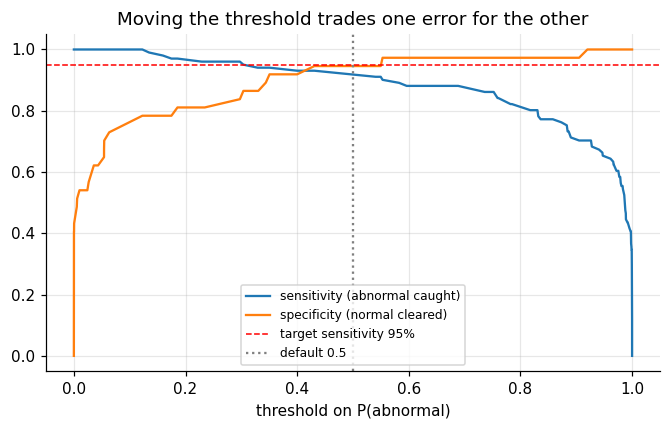

In [22]:
def choose_threshold(y_true, scores, target_sens):
    """Highest threshold whose sensitivity is still >= target_sens."""
    y_true = np.asarray(y_true).astype(int); scores = np.asarray(scores, dtype=float)
    n_abnormal = int(y_true.sum())
    chosen = float(scores.min())                                  # fallback: flag everything
    for t in np.unique(scores):                                   # sorted from low to high
        caught = int(((scores >= t) & (y_true == 1)).sum())
        if caught / n_abnormal >= target_sens:
            chosen = float(t)                                     # still meets the target -> remember it and look higher
        else:
            break                                                 # sensitivity only falls as t rises, so stop
    return chosen

t_sens = choose_threshold(yva, p_ens, TARGET_SENS)
at_05, at_t = evaluate(yva, p_ens, 0.5), evaluate(yva, p_ens, t_sens)
print(pd.DataFrame({"threshold": [0.5, round(t_sens, 3)],
                    "accuracy": [at_05["accuracy"], at_t["accuracy"]], "sensitivity": [at_05["sensitivity"], at_t["sensitivity"]],
                    "specificity": [at_05["specificity"], at_t["specificity"]], "missed": [at_05["fn"], at_t["fn"]],
                    "false_alarms": [at_05["fp"], at_t["fp"]]}).round(3).to_string(index=False))

sweep = pd.DataFrame([{"t": t, "sens": evaluate(yva, p_ens, t)["sensitivity"], "spec": evaluate(yva, p_ens, t)["specificity"]} for t in np.unique(np.round(p_ens, 6))])
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.plot(sweep["t"], sweep["sens"], label="sensitivity (abnormal caught)"); ax.plot(sweep["t"], sweep["spec"], label="specificity (normal cleared)")
ax.axhline(TARGET_SENS, color="red", ls="--", lw=1, label=f"target sensitivity {TARGET_SENS:.0%}"); ax.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax.set_xlabel("threshold on P(abnormal)"); ax.set_title("Moving the threshold trades one error for the other"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p5_threshold.png"); plt.show()

## 5.2 The honest check: what sensitivity will we really get on new cells?
Choosing the threshold *on* the validation images makes sensitivity 95% *on those same images* by construction. On new images it is usually a little lower.
**Out-of-bag bootstrap:** repeat many times: (1) re-draw the images with replacement, (2) the images **not** drawn are "new", (3) choose the threshold on the drawn ones, (4) measure it on the new ones, (5) look at the spread of the results.
We also try higher targets: asking for 97-99% on the chosen set is the price of *landing* near 95% on new data.

In [ ]:
def honest_check(y_true, scores, target, n_boot=None, seed=SEED):
    n_boot = n_boot or N_BOOT
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    rng = np.random.default_rng(seed); n = len(y_true); sens_list, spec_list = [], []
    for _ in range(n_boot):
        drawn = rng.integers(0, n, size=n)                        # (1) re-draw with replacement
        new = np.setdiff1d(np.arange(n), drawn)                   # (2) the never-drawn images = new data
        if y_true[drawn].sum() == 0 or y_true[new].sum() == 0 or (1 - y_true[new]).sum() == 0:
            continue
        t = choose_threshold(y_true[drawn], scores[drawn], target)        # (3)
        r = evaluate(y_true[new], scores[new], t)                          # (4)
        sens_list.append(r["sensitivity"]); spec_list.append(r["specificity"])
    return np.array(sens_list), np.array(spec_list)

rows = []
for target in [0.90, 0.95, 0.97, 0.99]:
    s, sp = honest_check(yva, p_ens, target)
    rows.append({"target on chosen set": target, "sens on NEW cells (median)": np.median(s), "sens 2.5%": np.percentile(s, 2.5),
                 "sens 97.5%": np.percentile(s, 97.5), "spec on NEW cells (median)": np.median(sp), "share of rounds reaching 95%": float((s >= 0.95).mean())})
honest = pd.DataFrame(rows).round(3)
print(honest.to_string(index=False))
row95 = honest[honest["target on chosen set"] == TARGET_SENS].iloc[0]
print(f"\nREAD THIS: asking for {TARGET_SENS:.0%} gives a typical {row95['sens on NEW cells (median)']:.1%} on new cells "
      f"(95% of rounds between {row95['sens 2.5%']:.1%} and {row95['sens 97.5%']:.1%}); 95% is actually reached in {row95['share of rounds reaching 95%']:.0%} of rounds.")
print("If that last share is low, choose a higher target from the table and accept the extra false alarms: for screening that is the safer choice.")

## 5.3 Calibration: can the score be read as a probability?
A model is **calibrated** if, among cells it scores about 0.8, roughly 80% are really abnormal. Fine-tuned networks are often over-confident, and a doctor who sees "95%" will trust it too much.
* **Reliability table:** split the scores into 5 bins; compare each bin's *average score* with its *real share of abnormal cells*. They should match.
* **ECE** (expected calibration error) = the weighted average gap (lower is better). **Brier score** = average squared gap between score and truth (lower is better).
* **Fix = Platt scaling:** a tiny logistic regression that learns "turn my score into a better probability" (a slope and an intercept). It keeps the ranking, so **AUC does not change**.
* **Fair test:** the calibrator is fitted by 5-fold cross-validation, so each cell is calibrated by a calibrator that never saw it. With ~138 images the bins hold few cells, so read the curve as a smoke alarm, not a measurement.

In [ ]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def reliability(y_true, probs, n_bins=5):
    """Per score bin: how many cells, mean score, real share abnormal. Also returns ECE."""
    edges = np.linspace(0, 1, n_bins + 1); rows, ece = [], 0.0
    for b in range(n_bins):
        lo, hi = edges[b], edges[b + 1]
        in_bin = (probs >= lo) & ((probs < hi) if b < n_bins - 1 else (probs <= hi))
        if in_bin.sum() == 0:
            continue
        mean_score, real_share = float(probs[in_bin].mean()), float(y_true[in_bin].mean())
        ece += (in_bin.sum() / len(y_true)) * abs(mean_score - real_share)
        rows.append({"score bin": f"{lo:.1f}-{hi:.1f}", "cells": int(in_bin.sum()), "mean score": round(mean_score, 3), "real share abnormal": round(real_share, 3)})
    return pd.DataFrame(rows), float(ece)

rel_before, ece_before = reliability(yva, p_ens)
p_cal = np.zeros_like(p_ens)
for train_i, hold_i in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(p_ens, yva):
    platt = LogisticRegression(C=1e6).fit(logit(p_ens[train_i]).reshape(-1, 1), yva[train_i])      # learn on 4/5 of the images
    p_cal[hold_i] = platt.predict_proba(logit(p_ens[hold_i]).reshape(-1, 1))[:, 1]                  # apply to the held-out 1/5
rel_after, ece_after = reliability(yva, p_cal)

print("BEFORE calibration"); print(rel_before.to_string(index=False))
print("\nAFTER calibration (cross-validated)"); print(rel_after.to_string(index=False))
print(f"\nBrier  before {brier_score_loss(yva, p_ens):.4f}  after {brier_score_loss(yva, p_cal):.4f}   (lower is better)")
print(f"ECE    before {ece_before:.4f}  after {ece_after:.4f}   (lower is better)")
print(f"AUC    before {roc_auc_score(yva, p_ens):.4f}  after {roc_auc_score(yva, p_cal):.4f}   (almost identical: ranking is unchanged)")

platt_final = LogisticRegression(C=1e6).fit(logit(p_ens).reshape(-1, 1), yva)         # the calibrator we keep: fitted on all validation images
platt_slope, platt_intercept = float(platt_final.coef_[0][0]), float(platt_final.intercept_[0])
print(f"\nFinal calibrator: calibrated = sigmoid({platt_slope:.3f} x logit(score) + {platt_intercept:.3f}). Slope below 1 = the model was over-confident; above 1 = under-confident.")

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.plot(rel_before["mean score"], rel_before["real share abnormal"], "o-", label=f"raw (ECE {ece_before:.3f})")
ax.plot(rel_after["mean score"], rel_after["real share abnormal"], "s-", label=f"calibrated (ECE {ece_after:.3f})")
ax.set_xlabel("mean predicted P(abnormal)"); ax.set_ylabel("real share abnormal"); ax.set_title("Reliability: closer to the diagonal is better"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p5_calibration.png"); plt.show()

## 5.4 Three-zone triage: clear / human review / flag
One threshold forces a yes-or-no on every cell, even the ones the model is unsure about. In practice we use **two** thresholds:
| Zone | Score | What happens |
|---|---|---|
| **Auto-clear** | below `t_low` | almost surely normal, no human needed. **The dangerous zone**: nobody double-checks it, so very few abnormal cells may sit here |
| **Human review** | in between | the model is unsure, so a cytologist looks |
| **Auto-flag** | at or above `t_high` | almost surely abnormal, sent to follow-up; mistakes here are false alarms that a later check catches |

`t_low` = the **highest** cut such that at most 2% of abnormal cells fall below it. `t_high` = the **lowest** cut such that at least 90% of the cells above it are really abnormal.
**Safety floor:** on small data a strong model can make the two cut-offs meet, which would claim "no human is needed at all". We do not believe that from ~138 images, so at least 10% of cells always go to a human.

In [ ]:
def choose_triage(y_true, scores, max_miss, min_ppv, min_human):
    y_true = np.asarray(y_true).astype(int); scores = np.asarray(scores, dtype=float)
    n_abnormal = int(y_true.sum()); cuts = np.unique(scores)

    t_low = float(cuts.min())
    for t in cuts:                                                # low -> high: how many abnormal cells fall BELOW t?
        if int(((scores < t) & (y_true == 1)).sum()) / n_abnormal <= max_miss:
            t_low = float(t)
        else:
            break
    t_high = float(cuts.max()) + 1e-6
    for t in cuts[::-1]:                                          # high -> low: how precise are the cells at or above t?
        if y_true[scores >= t].mean() >= min_ppv:
            t_high = float(t)
        else:
            break
    t_high = max(t_high, t_low)
    for t in cuts[cuts >= t_high]:                                # safety floor: raise t_high until enough cells go to a human
        if ((scores >= t_low) & (scores < t)).mean() >= min_human:
            t_high = float(t)
            break
    else:
        t_high = float(cuts.max()) + 1e-6
    return t_low, t_high

def triage_table(y_true, scores, t_low, t_high):
    zone = np.where(scores < t_low, "auto-clear", np.where(scores >= t_high, "auto-flag", "human review"))
    rows = []
    for name in ["auto-clear", "human review", "auto-flag"]:
        m = zone == name
        rows.append({"zone": name, "cells": int(m.sum()), "share of all cells": round(float(m.mean()), 3),
                     "truly abnormal": int(y_true[m].sum()), "truly normal": int((1 - y_true[m]).sum())})
    return pd.DataFrame(rows), zone

t_low, t_high = choose_triage(yva, p_ens, AUTO_CLEAR_MISS, AUTO_FLAG_PPV, MIN_HUMAN_SHARE)
tri, zone_val = triage_table(yva, p_ens, t_low, t_high)
n_abn_val = int(yva.sum()); missed_in_clear = int(yva[zone_val == "auto-clear"].sum())
saved = float((zone_val != "human review").mean())
print(f"t_low = {t_low:.3f}   t_high = {t_high:.3f}\n"); print(tri.to_string(index=False))
print(f"\nWorkload saved (cells needing NO human): {saved:.1%}  -> a human reads {1 - saved:.1%} of cells instead of 100%")
print(f"Abnormal cells in the auto-clear zone (missed with no second look): {missed_in_clear} of {n_abn_val} = {missed_in_clear / n_abn_val:.1%}   (limit {AUTO_CLEAR_MISS:.0%})")
print(f"Normal cells auto-flagged (false alarms): {int((1 - yva[zone_val == 'auto-flag']).sum())}")
if saved < 0.2:
    print("NOTE: very little workload is saved: the model is not confident enough yet. That is an honest result, not a bug.")
print("CAUTION: thresholds were tuned on this validation set, so these numbers are optimistic. The test set (last cell) gives the honest check.")

fig, ax = plt.subplots(figsize=(6.4, 3.8)); bins = np.linspace(0, 1, 26)
ax.hist(p_ens[yva == 0], bins=bins, alpha=0.6, label="truly normal"); ax.hist(p_ens[yva == 1], bins=bins, alpha=0.6, label="truly abnormal")
ax.axvline(t_low, color="green", ls="--", label=f"t_low {t_low:.2f}"); ax.axvline(t_high, color="red", ls="--", label=f"t_high {t_high:.2f}")
ax.set_xlabel("P(abnormal)"); ax.set_ylabel("number of cells"); ax.set_title("Three zones: clear | human review | flag"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "figures" / "p5_triage.png"); plt.show()

operating_point = {"model": "resnet18", "seeds": SEEDS, "score": "mean over seeds of flip-averaged P(abnormal)",
                   "threshold_for_target_sensitivity": {"target": TARGET_SENS, "threshold": t_sens, "val_sensitivity": at_t["sensitivity"], "val_specificity": at_t["specificity"],
                                                        "honest_sensitivity_on_new_cells_median": float(row95["sens on NEW cells (median)"])},
                   "calibration": {"method": "Platt scaling on logit(score)", "slope": platt_slope, "intercept": platt_intercept, "ece_before": ece_before, "ece_after_cv": ece_after},
                   "triage": {"t_low": t_low, "t_high": t_high, "workload_saved": saved, "abnormal_in_auto_clear": missed_in_clear, "n_abnormal_val": n_abn_val},
                   "caveats": ["thresholds chosen on the validation set (optimistic)", "small validation set -> wide intervals", "research prototype, not a medical device"]}
(OUT / "tables" / "operating_point.json").write_text(json.dumps(operating_point, indent=2))

### What just happened in Part 5, and why
* **Threshold:** we saw that 0.5 is only a default and found the cut-off that catches at least 95% of abnormal cells, with its price in false alarms.
* **Honest check:** we measured how much of that sensitivity survives on cells the threshold was *not* chosen on. This is the part most student projects skip, and it is what turns "95%" into a statement you can defend.
* **Calibration:** we tested whether the model's percentages can be trusted and fixed them with Platt scaling, checked fairly with cross-validation. Calibration does not change which cells rank higher, only what the numbers mean.
* **Triage:** instead of forcing a yes / no on every cell, we let the model say "I am sure it is normal", "I am sure it is abnormal", or "ask a human". The headline number is **workload saved** against **abnormal cells that slip into auto-clear**. That is the "makes change" sentence of the project.
* **Why the safety floor?** Tuned on 138 cells, any rule looks better than it will on new cells. Keeping at least 10% for human review keeps the claim modest.

**How to explain it in the review:** "A score is not a decision. We chose a threshold for at least 95% sensitivity, measured honestly how much of that holds on new cells, calibrated the probabilities, and built a three-zone triage that reports workload saved and the abnormal cells missed with no second look."

# FINAL - The one-time test-set evaluation
Every number above came from the **validation** set, which also guided early stopping and the thresholds. That makes them a little optimistic.
The **test set** was never used for any decision. It gives the honest final number, but it can be used **only once**: if you look, change something and look again, it stops being a test.

**When to run it:** only when everything above is final. Then set `RUN_FINAL_TEST = True` in Part 0 and run this cell.
It loads every seed's model, predicts the test images (with flip-averaging), averages the seeds, and reports accuracy (with a 95% CI), sensitivity, specificity and AUC at **0.5** and at the **Step 5 threshold**,
plus the three-zone triage table using the thresholds fixed on validation. It refuses to run a second time.

In [ ]:
test_file = OUT / "tables" / "test_result.json"
if not RUN_FINAL_TEST:
    print("The test set stays LOCKED (RUN_FINAL_TEST = False). Finish everything else first, then switch it on once.")
elif test_file.exists():
    print("STOP: the test set was already used once (test_result.json exists). It must not be reused.")
else:
    Xte = X[test_idx]; yte = df.loc[test_idx, "is_abnormal"].to_numpy()
    test_scores = []
    for seed in SEEDS:                                           # load each seed's model and score the test images
        model = keras.models.load_model(OUT / "models" / f"resnet18_seed{seed}.keras")
        test_scores.append(predict_scores(model, Xte)); keras.backend.clear_session(); gc.collect()
    p_test = np.mean(test_scores, axis=0)

    print(f"TEST SET: {len(yte)} images, always-abnormal accuracy {yte.mean():.3f}\n")
    result = {"n_test": int(len(yte)), "always_abnormal_accuracy": float(yte.mean()), "results": {}}
    for label, t in [("threshold 0.5", 0.5), (f"Step 5 threshold for {TARGET_SENS:.0%} sensitivity ({t_sens:.3f})", t_sens)]:
        r = evaluate(yte, p_test, t); low, high = bootstrap_ci(yte, p_test, "accuracy", threshold=t)
        result["results"][label] = {"threshold": float(t), "accuracy": float(r["accuracy"]), "accuracy_ci95": [float(low), float(high)], "sensitivity": float(r["sensitivity"]),
                                    "specificity": float(r["specificity"]), "roc_auc": float(r["roc_auc"]), "missed": int(r["fn"]), "false_alarms": int(r["fp"])}
        print(f"@ {label}: accuracy {r['accuracy']:.3f} (95% CI {low:.3f} to {high:.3f}) | sensitivity {r['sensitivity']:.3f} | specificity {r['specificity']:.3f} | AUC {r['roc_auc']:.3f} | missed {r['fn']} | false alarms {r['fp']}")
    tri_test, zone_test = triage_table(yte, p_test, t_low, t_high)
    print("\nTHREE-ZONE TRIAGE ON THE TEST SET (thresholds fixed on validation)"); print(tri_test.to_string(index=False))
    missed_test = int(yte[zone_test == "auto-clear"].sum())
    print(f"Workload saved: {float((zone_test != 'human review').mean()):.1%} | abnormal cells in auto-clear: {missed_test} of {int(yte.sum())}")
    result["triage"] = {"workload_saved": float((zone_test != "human review").mean()), "abnormal_in_auto_clear": missed_test, "n_abnormal_test": int(yte.sum())}
    test_file.write_text(json.dumps(result, indent=2))
    print(f"\nTARGET: accuracy >= 90% on the TEST set at threshold 0.5 -> {'MET' if result['results']['threshold 0.5']['accuracy'] >= 0.90 else 'NOT MET'}")
    print("Saved test_result.json. The test set is now USED; do not change anything and look again.")

# Summary: what to say in the review
1. **Data (Parts 1-2):** 917 cell images, 7 classes, 74% abnormal. We removed masks, cleaned duplicates, grouped near-copies, and split 70 / 15 / 15 by group and stratified by class, so no cell family is in two splits.
2. **Measurement (Part 3):** accuracy alone is misleading under imbalance, so we report sensitivity, specificity, MCC and AUC with bootstrap confidence intervals. A Random Forest on hand-made features is the bar.
3. **Model (Part 4):** ImageNet-pretrained ResNet18, fine-tuned in two phases, 3 seeds averaged with flip-averaging; accuracy reported with a 95% CI.
4. **Decision (Part 5):** threshold for >= 95% sensitivity, honest out-of-bag check, calibrated probabilities, and a three-zone triage with workload saved.
5. **Honesty:** validation numbers are slightly optimistic; the test set is used once; this is a research prototype on single-cell images, not a medical device.

**Files saved in `sgp_cervical/` on your Drive:** `tables/` (manifest, splits, baseline_bar, operating_point, test_result), `figures/` (all charts), `models/` (one `.keras` file per seed), `preds/` (validation scores and training histories).